In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
apps = pd.read_csv("googleplaystore.csv")

reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("Apps Dataset Shape:", apps.shape)
print("Reviews Dataset Shape:", reviews.shape)

Apps Dataset Shape: (10841, 13)
Reviews Dataset Shape: (64295, 5)


In [3]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
apps.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [5]:
apps['Rating'].describe()

count    9367.000000
mean        4.193338
std         0.537431
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64

In [6]:
apps['Category'].value_counts()

Category
FAMILY                 1972
GAME                   1144
TOOLS                   843
MEDICAL                 463
BUSINESS                460
PRODUCTIVITY            424
PERSONALIZATION         392
COMMUNICATION           387
SPORTS                  384
LIFESTYLE               382
FINANCE                 366
HEALTH_AND_FITNESS      341
PHOTOGRAPHY             335
SOCIAL                  295
NEWS_AND_MAGAZINES      283
SHOPPING                260
TRAVEL_AND_LOCAL        258
DATING                  234
BOOKS_AND_REFERENCE     231
VIDEO_PLAYERS           175
EDUCATION               156
ENTERTAINMENT           149
MAPS_AND_NAVIGATION     137
FOOD_AND_DRINK          127
HOUSE_AND_HOME           88
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
1.9                       1
Name: count, dtype: int64

In [7]:
pd.set_option('display.max_rows', None)

apps['Category'].value_counts()

Category
FAMILY                 1972
GAME                   1144
TOOLS                   843
MEDICAL                 463
BUSINESS                460
PRODUCTIVITY            424
PERSONALIZATION         392
COMMUNICATION           387
SPORTS                  384
LIFESTYLE               382
FINANCE                 366
HEALTH_AND_FITNESS      341
PHOTOGRAPHY             335
SOCIAL                  295
NEWS_AND_MAGAZINES      283
SHOPPING                260
TRAVEL_AND_LOCAL        258
DATING                  234
BOOKS_AND_REFERENCE     231
VIDEO_PLAYERS           175
EDUCATION               156
ENTERTAINMENT           149
MAPS_AND_NAVIGATION     137
FOOD_AND_DRINK          127
HOUSE_AND_HOME           88
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
1.9                       1
Name: count, dtype: int64

In [8]:
print("Total unique categories:", apps['Category'].nunique())

print("\nLast 5 categories:")
print(apps['Category'].value_counts().tail(5))

Total unique categories: 34

Last 5 categories:
Category
EVENTS       64
COMICS       60
PARENTING    60
BEAUTY       53
1.9           1
Name: count, dtype: int64


In [9]:
print("Total duplicate app names:", apps['App'].duplicated().sum())

Total duplicate app names: 1181


In [10]:
print("Total exact duplicate rows:", apps.duplicated().sum())

Total exact duplicate rows: 483


In [11]:
apps.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [12]:
missing_percentage = (apps.isnull().sum() / len(apps)) * 100

print(missing_percentage[missing_percentage > 0].round(2))

Rating            13.60
Type               0.01
Content Rating     0.01
Current Ver        0.07
Android Ver        0.03
dtype: float64


In [13]:
reviews.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [14]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 2.5 MB


In [15]:
missing_reviews = (reviews.isnull().sum() / len(reviews)) * 100

print(missing_reviews[missing_reviews > 0].round(2))

Translated_Review         41.79
Sentiment                 41.78
Sentiment_Polarity        41.78
Sentiment_Subjectivity    41.78
dtype: float64


In [16]:
reviews['Sentiment'].value_counts()

Sentiment
Positive    23998
Negative     8271
Neutral      5163
Name: count, dtype: int64

In [17]:
sentiment_percentage = (
    reviews['Sentiment'].value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

Sentiment
Positive    64.11
Negative    22.10
Neutral     13.79
Name: proportion, dtype: float64


In [18]:
reviews['Sentiment_Polarity'].describe()

count    37432.000000
mean         0.182146
std          0.351301
min         -1.000000
25%          0.000000
50%          0.150000
75%          0.400000
max          1.000000
Name: Sentiment_Polarity, dtype: float64

In [19]:
reviews['Sentiment_Subjectivity'].describe()

count    37432.000000
mean         0.492704
std          0.259949
min          0.000000
25%          0.357143
50%          0.514286
75%          0.650000
max          1.000000
Name: Sentiment_Subjectivity, dtype: float64

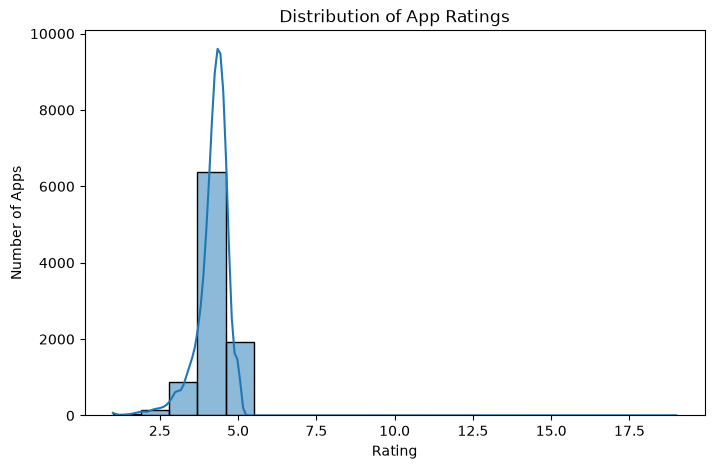

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(apps['Rating'].dropna(), bins=20, kde=True)

plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')

plt.show()

In [21]:
category_ratings = apps.groupby('Category')['Rating'].mean().sort_values(ascending=False)

print(category_ratings)

Category
1.9                    19.000000
EVENTS                  4.435556
EDUCATION               4.389032
ART_AND_DESIGN          4.358065
BOOKS_AND_REFERENCE     4.346067
PERSONALIZATION         4.335987
PARENTING               4.300000
GAME                    4.286326
BEAUTY                  4.278571
HEALTH_AND_FITNESS      4.277104
SHOPPING                4.259664
SOCIAL                  4.255598
WEATHER                 4.244000
SPORTS                  4.223511
PRODUCTIVITY            4.211396
HOUSE_AND_HOME          4.197368
FAMILY                  4.192272
PHOTOGRAPHY             4.192114
AUTO_AND_VEHICLES       4.190411
MEDICAL                 4.189143
LIBRARIES_AND_DEMO      4.178462
FOOD_AND_DRINK          4.166972
COMMUNICATION           4.158537
COMICS                  4.155172
NEWS_AND_MAGAZINES      4.132189
FINANCE                 4.131889
ENTERTAINMENT           4.126174
BUSINESS                4.121452
TRAVEL_AND_LOCAL        4.109292
LIFESTYLE               4.094904
V

In [22]:
valid_apps = apps[
    (apps['Rating'].between(1, 5)) &
    (apps['Category'] != '1.9')
]

category_ratings = valid_apps.groupby('Category')['Rating'].mean()

print("Top 5 Categories:")
print(category_ratings.sort_values(ascending=False).head(5))

print("\nBottom 5 Categories:")
print(category_ratings.sort_values().head(5))

Top 5 Categories:
Category
EVENTS                 4.435556
EDUCATION              4.389032
ART_AND_DESIGN         4.358065
BOOKS_AND_REFERENCE    4.346067
PERSONALIZATION        4.335987
Name: Rating, dtype: float64

Bottom 5 Categories:
Category
DATING                 3.970769
TOOLS                  4.047411
MAPS_AND_NAVIGATION    4.051613
VIDEO_PLAYERS          4.063750
LIFESTYLE              4.094904
Name: Rating, dtype: float64


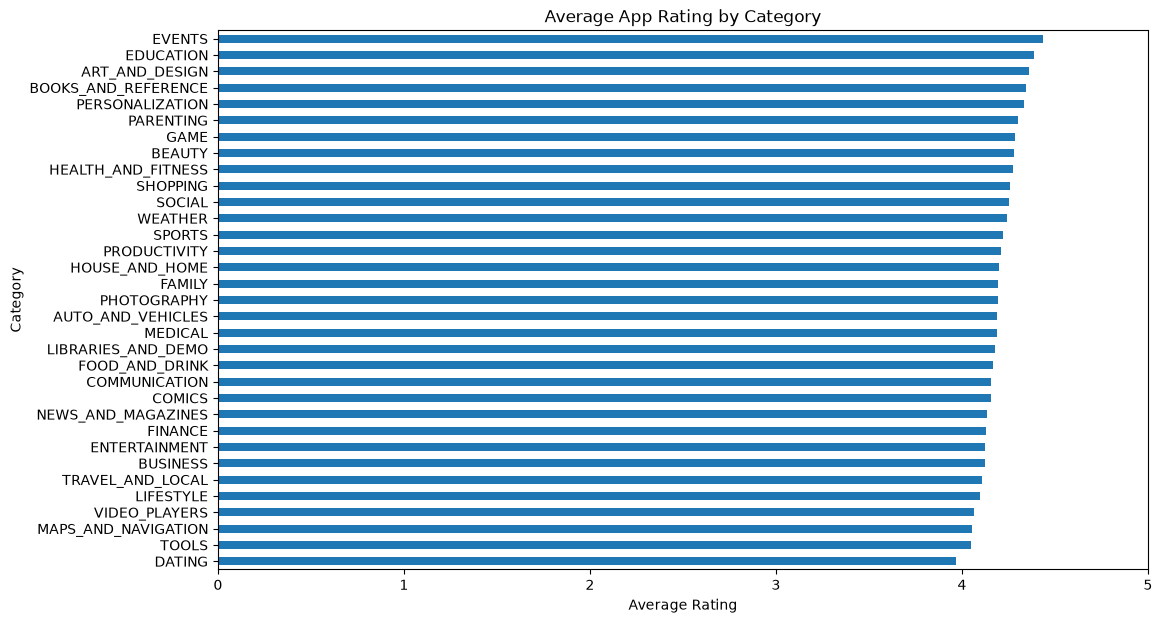

In [23]:
plt.figure(figsize=(12, 7))

category_ratings.sort_values().plot(kind='barh')

plt.title('Average App Rating by Category')
plt.xlabel('Average Rating')
plt.ylabel('Category')
plt.xlim(0, 5)

plt.show()

In [24]:
print(apps['Type'].value_counts())

Type
Free    10039
Paid      800
0           1
Name: count, dtype: int64


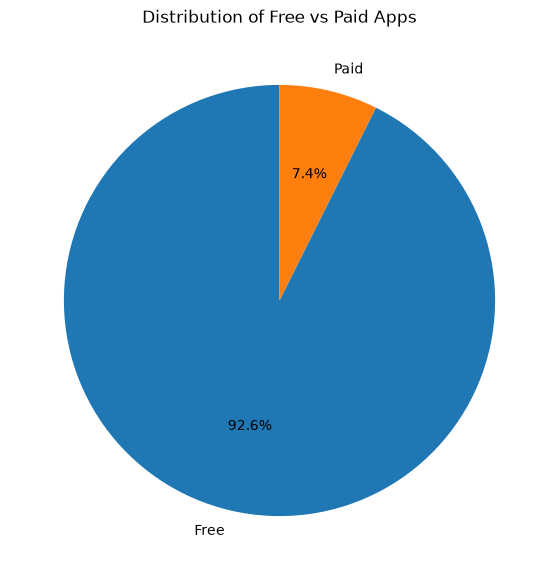

In [25]:
type_counts = apps['Type'].value_counts().reindex(['Free', 'Paid'])

plt.figure(figsize=(7, 7))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Free vs Paid Apps')
plt.show()

In [26]:
paid_apps = apps[apps['Type'] == 'Paid'].copy()

paid_apps['Price'] = (
    paid_apps['Price']
    .str.replace('$', '', regex=False)
    .astype(float)
)

paid_apps['Price'].describe()

count    800.000000
mean      13.920838
std       57.195358
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

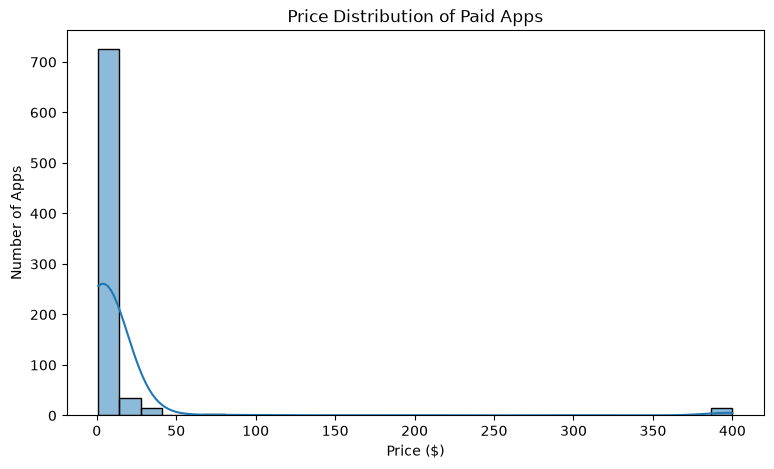

In [27]:
plt.figure(figsize=(9, 5))

sns.histplot(paid_apps['Price'], bins=30, kde=True)

plt.title('Price Distribution of Paid Apps')
plt.xlabel('Price ($)')
plt.ylabel('Number of Apps')

plt.show()

In [28]:
print("Unique Size values:")
print(apps['Size'].head(15).tolist())

print("\nUnique Installs values:")
print(apps['Installs'].head(15).tolist())

Unique Size values:
['19M', '14M', '8.7M', '25M', '2.8M', '5.6M', '19M', '29M', '33M', '3.1M', '28M', '12M', '20M', '21M', '37M']

Unique Installs values:
['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+', '50,000+', '50,000+', '1,000,000+', '1,000,000+', '10,000+', '1,000,000+', '1,000,000+', '10,000,000+', '100,000+', '100,000+']


In [29]:
print("Size special values:")
print(apps['Size'].value_counts().tail(10))

print("\nInstalls unique values:")
print(apps['Installs'].value_counts().tail(10))

Size special values:
Size
467k     1
157k     1
44k      1
676k     1
67k      1
552k     1
885k     1
1020k    1
582k     1
619k     1
Name: count, dtype: int64

Installs unique values:
Installs
500+              330
50,000,000+       289
50+               205
5+                 82
500,000,000+       72
1+                 67
1,000,000,000+     58
0+                 14
0                   1
Free                1
Name: count, dtype: int64


In [30]:
size_values = apps['Size'].unique()

unusual_sizes = [
    value for value in size_values
    if not (value.endswith('M') or value.endswith('k'))
]

print("Unusual Size Values:")
print(unusual_sizes)

Unusual Size Values:
['Varies with device', '1,000+']


In [31]:
unusual_records = apps[
    ~apps['Size'].str.endswith(('M', 'k'))
]

print("Total unusual records:", len(unusual_records))

print("\nSize value counts:")
print(unusual_records['Size'].value_counts())

print("\nRecords with 1,000+:")
print(
    unusual_records[unusual_records['Size'] == '1,000+']
    [['App', 'Size', 'Installs']]
)

Total unusual records: 1696

Size value counts:
Size
Varies with device    1695
1,000+                   1
Name: count, dtype: int64

Records with 1,000+:
                                           App    Size Installs
10472  Life Made WI-Fi Touchscreen Photo Frame  1,000+     Free


In [32]:
apps.loc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              1.9
Rating                                               19.0
Reviews                                              3.0M
Size                                               1,000+
Installs                                             Free
Type                                                    0
Price                                            Everyone
Content Rating                                        NaN
Genres                                  February 11, 2018
Last Updated                                       1.0.19
Current Ver                                    4.0 and up
Android Ver                                           NaN
Name: 10472, dtype: object

In [33]:
print("Size values ending with M:",
      apps[apps['Size'].str.endswith('M')]['Size'].shape[0])

print("Size values ending with k:",
      apps[apps['Size'].str.endswith('k')]['Size'].shape[0])

print("\nInstalls unique sample:")
print(apps['Installs'].unique()[:20])

Size values ending with M: 8829
Size values ending with k: 316

Installs unique sample:
<StringArray>
[       '10,000+',       '500,000+',     '5,000,000+',    '50,000,000+',
       '100,000+',        '50,000+',     '1,000,000+',    '10,000,000+',
         '5,000+',   '100,000,000+', '1,000,000,000+',         '1,000+',
   '500,000,000+',            '50+',           '100+',           '500+',
            '10+',             '1+',             '5+',             '0+']
Length: 20, dtype: str


In [34]:
print("Total unique install values:", apps['Installs'].nunique())

print("\nInstall values with unusual formats:")
print(
    apps[
        ~apps['Installs'].str.endswith('+')
    ]['Installs'].value_counts()
)

Total unique install values: 22

Install values with unusual formats:
Installs
0       1
Free    1
Name: count, dtype: int64


In [35]:
apps[
    apps['Installs'].isin(['0', 'Free'])
][['App', 'Category', 'Rating', 'Installs', 'Type', 'Price']]

,App,Category,Rating,Installs,Type,Price
9148,Command & Conquer: Rivals,FAMILY,NaN,0,NaN,0
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,Free,0,Everyone


In [36]:
print("Exact duplicate rows:",
      apps.duplicated().sum())

print("\nDuplicate app names:",
      apps['App'].duplicated().sum())

print("\nReviews exact duplicate rows:",
      reviews.duplicated().sum())

Exact duplicate rows: 483

Duplicate app names: 1181

Reviews exact duplicate rows: 33616


In [37]:
duplicate_reviews = reviews[
    reviews.duplicated(keep=False)
]

print("Total rows involved in duplicates:",
      len(duplicate_reviews))

print("\nSample duplicate reviews:")
display(duplicate_reviews.head(10))

Total rows involved in duplicates: 39968

Sample duplicate reviews:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000
6,10 Best Foods for You,Amazing,Positive,0.60,0.900000
7,10 Best Foods for You,NaN,NaN,NaN,NaN
8,10 Best Foods for You,"Looking forward app,",Neutral,0.00,0.000000
9,10 Best Foods for You,It helpful site ! It help foods get !,Neutral,0.00,0.000000


In [38]:
reviews_without_null = reviews.dropna(
    subset=['Translated_Review']
)

print("Total reviews without missing text:",
      len(reviews_without_null))

print("Exact duplicates excluding missing reviews:",
      reviews_without_null.duplicated().sum())

Total reviews without missing text: 37427


Exact duplicates excluding missing reviews: 7735


In [39]:
duplicate_app_names = apps[
    apps['App'].duplicated(keep=False)
]

display(
    duplicate_app_names[
        ['App', 'Category', 'Rating', 'Reviews', 'Type']
    ].head(15)
)

,App,Category,Rating,Reviews,Type
1,Coloring book moana,ART_AND_DESIGN,3.9,967,Free
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61,Free
36,UNICORN - Color By Number & Pixel Art Coloring,ART_AND_DESIGN,4.7,8145,Free
42,Textgram - write on photos,ART_AND_DESIGN,4.4,295221,Free
139,Wattpad 📖 Free Books,BOOKS_AND_REFERENCE,4.6,2914724,Free
143,Amazon Kindle,BOOKS_AND_REFERENCE,4.2,814080,Free
145,Dictionary - Merriam-Webster,BOOKS_AND_REFERENCE,4.5,454060,Free
146,NOOK: Read eBooks & Magazines,BOOKS_AND_REFERENCE,4.5,155446,Free
155,Oxford Dictionary of English : Free,BOOKS_AND_REFERENCE,4.1,363934,Free
157,Spanish English Translator,BOOKS_AND_REFERENCE,4.2,87873,Free


In [40]:
apps[
    apps['App'] == 'Instagram'
][['App', 'Category', 'Rating', 'Reviews', 'Size',
   'Installs', 'Type', 'Price', 'Last Updated']]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Last Updated
2545,Instagram,SOCIAL,4.5,66577313,Varies with device,"1,000,000,000+",Free,0,"July 31, 2018"
2604,Instagram,SOCIAL,4.5,66577446,Varies with device,"1,000,000,000+",Free,0,"July 31, 2018"
2611,Instagram,SOCIAL,4.5,66577313,Varies with device,"1,000,000,000+",Free,0,"July 31, 2018"
3909,Instagram,SOCIAL,4.5,66509917,Varies with device,"1,000,000,000+",Free,0,"July 31, 2018"


In [41]:
print("Apps dataset shape:", apps.shape)
print("\nApps data types:")
print(apps.dtypes)

print("\nReviews dataset shape:", reviews.shape)
print("\nReviews data types:")
print(reviews.dtypes)

Apps dataset shape: (10841, 13)

Apps data types:
App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

Reviews dataset shape: (64295, 5)

Reviews data types:
App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object


In [126]:
apps_clean = apps.copy()
reviews_clean = reviews.copy()

print("Apps working copy:", apps_clean.shape)
print("Reviews working copy:", reviews_clean.shape)

Apps working copy: (10841, 13)
Reviews working copy: (64295, 5)


In [127]:
before = apps_clean.shape[0]

apps_clean = apps_clean.drop_duplicates()

after = apps_clean.shape[0]

print("Rows before cleaning:", before)
print("Rows after cleaning:", after)
print("Duplicate rows removed:", before - after)

Rows before cleaning: 10841
Rows after cleaning: 10358
Duplicate rows removed: 483


In [128]:
apps_clean = apps_clean.drop(index=10472, errors='ignore')

print("Apps dataset shape:", apps_clean.shape)

Apps dataset shape: (10357, 13)


In [129]:
invalid_ratings = apps_clean[
    ~apps_clean['Rating'].between(1, 5)
    & apps_clean['Rating'].notna()
]

print("Invalid rating records:", len(invalid_ratings))

display(invalid_ratings[['App', 'Rating']])

Invalid rating records: 0


,App,Rating


In [130]:
print("Missing ratings:", apps_clean['Rating'].isnull().sum())

print("\nMissing rating percentage:",
      round(apps_clean['Rating'].isnull().mean() * 100, 2), "%")

Missing ratings: 1465

Missing rating percentage: 14.15 %


In [131]:
missing_apps = apps_clean.isnull().sum()

print("Missing values by column:")
print(missing_apps[missing_apps > 0])

print("\nTotal missing values:",
      apps_clean.isnull().sum().sum())

Missing values by column:
Rating         1465
Type              1
Current Ver       8
Android Ver       2
dtype: int64

Total missing values: 1476


In [132]:
apps_clean[apps_clean['Type'].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [133]:
print(
    apps_clean[
        apps_clean['Type'].notna()
    ].groupby('Type')['Price'].value_counts().head(15)
)

Type  Price  
Free  0          9591
Paid  $0.99       146
      $2.99       125
      $1.99        73
      $4.99        70
      $3.99        60
      $1.49        46
      $5.99        27
      $2.49        25
      $9.99        19
      $6.99        12
      $399.99      12
      $14.99        9
      $4.49         9
      $3.49         7
Name: count, dtype: int64


In [134]:
apps_clean.loc[
    apps_clean['Type'].isnull(), 'Type'
] = 'Free'

print("Missing Type values:",
      apps_clean['Type'].isnull().sum())

print("\nUpdated Type distribution:")
print(apps_clean['Type'].value_counts())

Missing Type values: 0

Updated Type distribution:
Type
Free    9592
Paid     765
Name: count, dtype: int64


In [135]:
apps_clean[
    apps_clean['Current Ver'].isnull()
][['App', 'Category', 'Rating', 'Current Ver', 'Android Ver']]

,App,Category,Rating,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,NaN,4.2 and up
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.1,NaN,1.5 and up
6322,Virtual DJ Sound Mixer,TOOLS,4.2,NaN,4.0 and up
6803,BT Master,FAMILY,NaN,NaN,1.6 and up
7333,Dots puzzle,FAMILY,4.0,NaN,4.0 and up
7407,Calculate My IQ,FAMILY,NaN,NaN,2.3 and up
7730,UFO-CQ,TOOLS,NaN,NaN,2.0 and up
10342,La Fe de Jesus,BOOKS_AND_REFERENCE,NaN,NaN,3.0 and up


In [136]:
apps_clean['Current Ver'] = apps_clean['Current Ver'].fillna('Unknown')

print("Missing Current Ver:",
      apps_clean['Current Ver'].isnull().sum())

Missing Current Ver: 0


In [137]:
apps_clean[
    apps_clean['Android Ver'].isnull()
][['App', 'Category', 'Current Ver', 'Android Ver']]

,App,Category,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,1.1,NaN


In [138]:
apps_clean['Android Ver'] = apps_clean['Android Ver'].fillna('Unknown')

print("Missing Android Ver:",
      apps_clean['Android Ver'].isnull().sum())

Missing Android Ver: 0


In [139]:
print("Missing values after cleaning:\n")
print(apps_clean.isnull().sum())

print("\nTotal missing values:",
      apps_clean.isnull().sum().sum())

Missing values after cleaning:

App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          0
Android Ver          0
dtype: int64

Total missing values: 1465


In [140]:
import numpy as np

def convert_size(size):
    if size == 'Varies with device':
        return np.nan

    elif size.endswith('M'):
        return float(size.replace('M', ''))

    elif size.endswith('k'):
        return float(size.replace('k', '')) / 1024

    return np.nan


apps_clean['Size_MB'] = apps_clean['Size'].apply(convert_size)

print(apps_clean[['Size', 'Size_MB']].head(15))

    Size  Size_MB
0    19M     19.0
1    14M     14.0
2   8.7M      8.7
3    25M     25.0
4   2.8M      2.8
5   5.6M      5.6
6    19M     19.0
7    29M     29.0
8    33M     33.0
9   3.1M      3.1
10   28M     28.0
11   12M     12.0
12   20M     20.0
13   21M     21.0
14   37M     37.0


In [141]:
print("Missing Size_MB values:",
      apps_clean['Size_MB'].isnull().sum())

print("\nSize_MB statistics:")
print(apps_clean['Size_MB'].describe())

print("\nSmallest converted sizes:")
print(apps_clean['Size_MB'].nsmallest(5))

Missing Size_MB values: 1526

Size_MB statistics:
count    8831.000000
mean       21.287413
std        22.540591
min         0.008301
25%         4.700000
50%        13.000000
75%        29.000000
max       100.000000
Name: Size_MB, dtype: float64

Smallest converted sizes:
1532     0.008301
1553     0.010742
4983     0.013672
4977     0.016602
10072    0.016602
Name: Size_MB, dtype: float64


In [142]:
print("Original Size categories after cleaning:")
print(apps_clean['Size'].value_counts().tail(5))

print("\nSize_MB missing by original Size:")
print(
    apps_clean.loc[
        apps_clean['Size_MB'].isnull(),
        'Size'
    ].value_counts()
)

Original Size categories after cleaning:
Size
552k     1
885k     1
1020k    1
582k     1
619k     1
Name: count, dtype: int64

Size_MB missing by original Size:
Size
Varies with device    1526
Name: count, dtype: int64


In [143]:
apps_clean['Installs_Numeric'] = (
    apps_clean['Installs']
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)

apps_clean['Installs_Numeric'] = pd.to_numeric(
    apps_clean['Installs_Numeric'],
    errors='coerce'
)

print(apps_clean[['Installs', 'Installs_Numeric']].head(15))

       Installs  Installs_Numeric
0       10,000+             10000
1      500,000+            500000
2    5,000,000+           5000000
3   50,000,000+          50000000
4      100,000+            100000
5       50,000+             50000
6       50,000+             50000
7    1,000,000+           1000000
8    1,000,000+           1000000
9       10,000+             10000
10   1,000,000+           1000000
11   1,000,000+           1000000
12  10,000,000+          10000000
13     100,000+            100000
14     100,000+            100000


In [144]:
print("Missing Installs_Numeric:",
      apps_clean['Installs_Numeric'].isnull().sum())

print("\nInstalls statistics:")
print(apps_clean['Installs_Numeric'].describe())

print("\nUnusual original Installs values:")
print(
    apps_clean[
        apps_clean['Installs_Numeric'].isnull()
    ]['Installs'].value_counts()
)

Missing Installs_Numeric: 0

Installs statistics:
count    1.035700e+04
mean     1.415776e+07
std      8.023955e+07
min      0.000000e+00
25%      1.000000e+03
50%      1.000000e+05
75%      1.000000e+06
max      1.000000e+09
Name: Installs_Numeric, dtype: float64

Unusual original Installs values:
Series([], Name: count, dtype: int64)


In [145]:
print("Unique Price values:", apps_clean['Price'].nunique())

print("\nSample Price values:")
print(apps_clean['Price'].unique()[:30])

print("\nPrice value counts:")
print(apps_clean['Price'].value_counts().head(15))

Unique Price values: 92

Sample Price values:
<StringArray>
[     '0',  '$4.99',  '$3.99',  '$6.99',  '$1.49',  '$2.99',  '$7.99',
  '$5.99',  '$3.49',  '$1.99',  '$9.99',  '$7.49',  '$0.99',  '$9.00',
  '$5.49', '$10.00', '$24.99', '$11.99', '$79.99', '$16.99', '$14.99',
  '$1.00', '$29.99', '$12.99',  '$2.49', '$10.99',  '$1.50', '$19.99',
 '$15.99', '$33.99']
Length: 30, dtype: str

Price value counts:
Price
0          9592
$0.99       146
$2.99       125
$1.99        73
$4.99        70
$3.99        60
$1.49        46
$5.99        27
$2.49        25
$9.99        19
$6.99        12
$399.99      12
$14.99        9
$4.49         9
$7.99         7
Name: count, dtype: int64


In [146]:
apps_clean['Price_Numeric'] = pd.to_numeric(
    apps_clean['Price'].str.replace('$', '', regex=False),
    errors='coerce'
)

print(apps_clean[['Price', 'Price_Numeric']].head(15))

   Price  Price_Numeric
0      0            0.0
1      0            0.0
2      0            0.0
3      0            0.0
4      0            0.0
5      0            0.0
6      0            0.0
7      0            0.0
8      0            0.0
9      0            0.0
10     0            0.0
11     0            0.0
12     0            0.0
13     0            0.0
14     0            0.0


In [147]:
apps_clean.loc[apps_clean['Price_Numeric'] > 0, ['App', 'Price', 'Price_Numeric']].head(10)

,App,Price,Price_Numeric
234,TurboScan: scan documents and receipts in PDF,$4.99,4.99
235,Tiny Scanner Pro: PDF Doc Scan,$4.99,4.99
427,Puffin Browser Pro,$3.99,3.99
476,"Moco+ - Chat, Meet People",$3.99,3.99
477,Calculator,$6.99,6.99
478,Truth or Dare Pro,$1.49,1.49
479,"Private Dating, Hide App- Blue for PrivacyHider",$2.99,2.99
480,Ad Blocker for SayHi,$3.99,3.99
481,AMBW Dating App: Asian Men Black Women Interra...,$7.99,7.99
571,"Moco+ - Chat, Meet People",$3.99,3.99


In [148]:
print("Missing Prices:", apps_clean['Price_Numeric'].isnull().sum())

print("\nPrice Statistics:")
print(apps_clean['Price_Numeric'].describe())

Missing Prices: 0

Price Statistics:
count    10357.000000
mean         1.030800
std         16.278625
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        400.000000
Name: Price_Numeric, dtype: float64


In [149]:
print("Reviews Shape:", reviews_clean.shape)

print("\nMissing Values:")
print(reviews_clean.isnull().sum())

print("\nExact Duplicate Rows:", reviews_clean.duplicated().sum())

Reviews Shape: (64295, 5)

Missing Values:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

Exact Duplicate Rows: 33616


In [150]:
print("Missing Review Text:")
print(reviews_clean[reviews_clean['Translated_Review'].isnull()].head(10))

print("\nMissing Sentiment:")
print(reviews_clean[reviews_clean['Sentiment'].isnull()].head(10))

Missing Review Text:
                                                  App Translated_Review  \
2                               10 Best Foods for You               NaN   
7                               10 Best Foods for You               NaN   
15                              10 Best Foods for You               NaN   
102                             10 Best Foods for You               NaN   
107                             10 Best Foods for You               NaN   
115                             10 Best Foods for You               NaN   
268                                              11st               NaN   
362                   1LINE – One Line with One Touch               NaN   
368                   1LINE – One Line with One Touch               NaN   
405  2018Emoji Keyboard 😂 Emoticons Lite -sticker&gif               NaN   

    Sentiment  Sentiment_Polarity  Sentiment_Subjectivity  
2         NaN                 NaN                     NaN  
7         NaN                 NaN

In [151]:
print("Missing Review Text:", reviews_clean['Translated_Review'].isnull().sum())

print("\nMissing Text but Sentiment Available:")
print(
    reviews_clean[
        reviews_clean['Translated_Review'].isnull() &
        reviews_clean['Sentiment'].notnull()
    ].shape[0]
)

print("\nMissing Text and Sentiment:")
print(
    reviews_clean[
        reviews_clean['Translated_Review'].isnull() &
        reviews_clean['Sentiment'].isnull()
    ].shape[0]
)

Missing Review Text: 26868

Missing Text but Sentiment Available:


5

Missing Text and Sentiment:
26863


In [152]:
reviews_clean = reviews_clean.dropna(subset=['Translated_Review'])

print("Updated Reviews Shape:", reviews_clean.shape)

print("\nMissing Values:")
print(reviews_clean.isnull().sum())

Updated Reviews Shape: (37427, 5)

Missing Values:
App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64


In [153]:
print("Exact Duplicate Rows:", reviews_clean.duplicated().sum())

print("\nDuplicate Review Samples:")
print(
    reviews_clean[
        reviews_clean.duplicated(keep=False)
    ].sort_values('App').head(10)
)

Exact Duplicate Rows: 7735

Duplicate Review Samples:
                       App                                  Translated_Review  \
0    10 Best Foods for You  I like eat delicious food. That's I'm cooking ...   
131  10 Best Foods for You  Thanks advice. Downloaded Adobe reader still c...   
132  10 Best Foods for You                 No recipe book Unable recipe book.   
133  10 Best Foods for You                     Absolutely Fabulous Phenomenal   
134  10 Best Foods for You                                    Great Love food   
135  10 Best Foods for You                          Excellent It really works   
136  10 Best Foods for You                                               Best   
137  10 Best Foods for You  WEALTH OF INFORMATION Very informative ... eas...   
138  10 Best Foods for You                               Not description good   
139  10 Best Foods for You                                    Great app. Love   

    Sentiment  Sentiment_Polarity  Sentiment_Subjectiv

In [154]:
reviews_clean = reviews_clean.drop_duplicates()

print("Updated Reviews Shape:", reviews_clean.shape)

print("Remaining Duplicates:", reviews_clean.duplicated().sum())

Updated Reviews Shape: (29692, 5)
Remaining Duplicates: 0


In [155]:
print("Unique Sentiments:")
print(reviews_clean['Sentiment'].unique())

print("\nSentiment Distribution:")
print(reviews_clean['Sentiment'].value_counts())

print("\nSentiment Percentages:")
print(
    reviews_clean['Sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Unique Sentiments:
<StringArray>
['Positive', 'Neutral', 'Negative']
Length: 3, dtype: str

Sentiment Distribution:
Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64

Sentiment Percentages:
Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: proportion, dtype: float64


In [156]:
print("Polarity Statistics:")
print(reviews_clean['Sentiment_Polarity'].describe())

print("\nSubjectivity Statistics:")
print(reviews_clean['Sentiment_Subjectivity'].describe())

print("\nPolarity outside -1 to 1:",
      ((reviews_clean['Sentiment_Polarity'] < -1) |
       (reviews_clean['Sentiment_Polarity'] > 1)).sum())

print("Subjectivity outside 0 to 1:",
      ((reviews_clean['Sentiment_Subjectivity'] < 0) |
       (reviews_clean['Sentiment_Subjectivity'] > 1)).sum())

Polarity Statistics:
count    29692.000000
mean         0.188868
std          0.355694
min         -1.000000
25%          0.000000
50%          0.157143
75%          0.422917
max          1.000000
Name: Sentiment_Polarity, dtype: float64

Subjectivity Statistics:
count    29692.000000
mean         0.490930
std          0.265976
min          0.000000
25%          0.350000
50%          0.514286
75%          0.652703
max          1.000000
Name: Sentiment_Subjectivity, dtype: float64

Polarity outside -1 to 1: 0
Subjectivity outside 0 to 1: 0


In [157]:
print("APPS CLEANED DATASET")
print("Shape:", apps_clean.shape)
print("Duplicates:", apps_clean.duplicated().sum())
print("Total Missing Values:", apps_clean.isnull().sum().sum())

print("\nREVIEWS CLEANED DATASET")
print("Shape:", reviews_clean.shape)
print("Duplicates:", reviews_clean.duplicated().sum())
print("Total Missing Values:", reviews_clean.isnull().sum().sum())

APPS CLEANED DATASET
Shape: (10357, 16)
Duplicates: 0
Total Missing Values: 2991

REVIEWS CLEANED DATASET
Shape: (29692, 5)
Duplicates: 0
Total Missing Values: 0


In [158]:
category_counts = apps_clean['Category'].value_counts()

print(category_counts)

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
Name: count, dtype: int64


In [159]:
top_10_categories = category_counts.head(10)

print(top_10_categories)

Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64


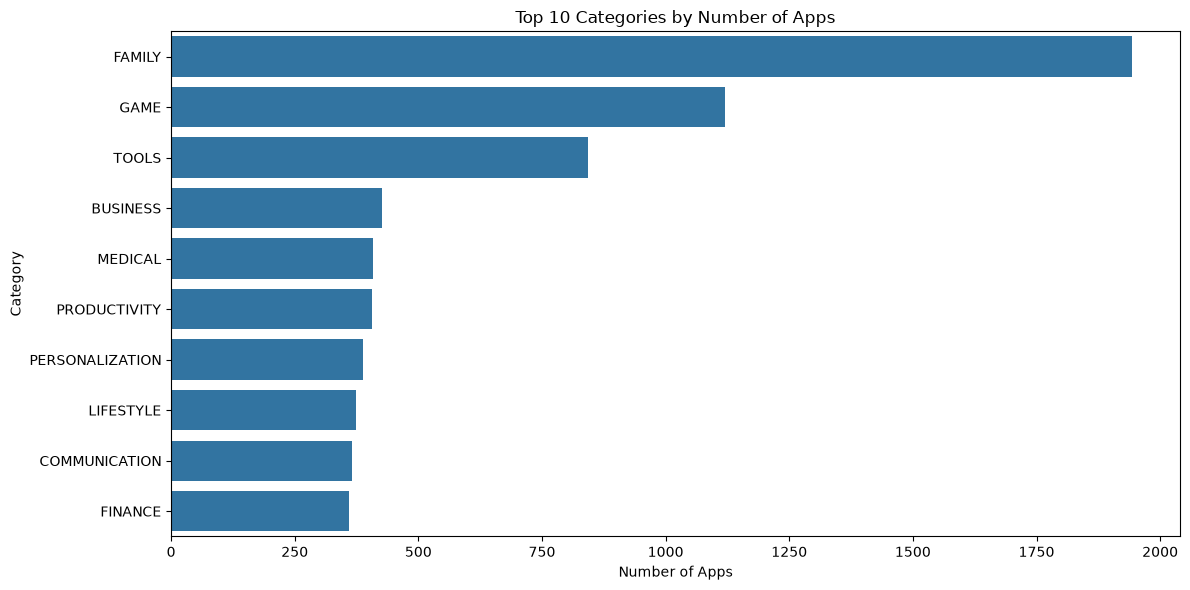

In [160]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title('Top 10 Categories by Number of Apps')
plt.xlabel('Number of Apps')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

In [161]:
category_ratings = (
    apps_clean.groupby('Category')['Rating']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Categories by Average Rating:")
print(category_ratings.head(10))

Top 10 Categories by Average Rating:
Category
EVENTS                 4.435556
EDUCATION              4.375969
ART_AND_DESIGN         4.358065
BOOKS_AND_REFERENCE    4.347458
PERSONALIZATION        4.333871
PARENTING              4.300000
GAME                   4.281285
BEAUTY                 4.278571
HEALTH_AND_FITNESS     4.261450
SOCIAL                 4.254918
Name: Rating, dtype: float64


In [162]:
print("Bottom 10 Categories by Average Rating:")
print(category_ratings.tail(10).sort_values())

Bottom 10 Categories by Average Rating:
Category
DATING                 3.971698
TOOLS                  4.047411
MAPS_AND_NAVIGATION    4.051613
VIDEO_PLAYERS          4.063750
TRAVEL_AND_LOCAL       4.094146
LIFESTYLE              4.096066
BUSINESS               4.102593
FINANCE                4.127445
NEWS_AND_MAGAZINES     4.128505
ENTERTAINMENT          4.136036
Name: Rating, dtype: float64


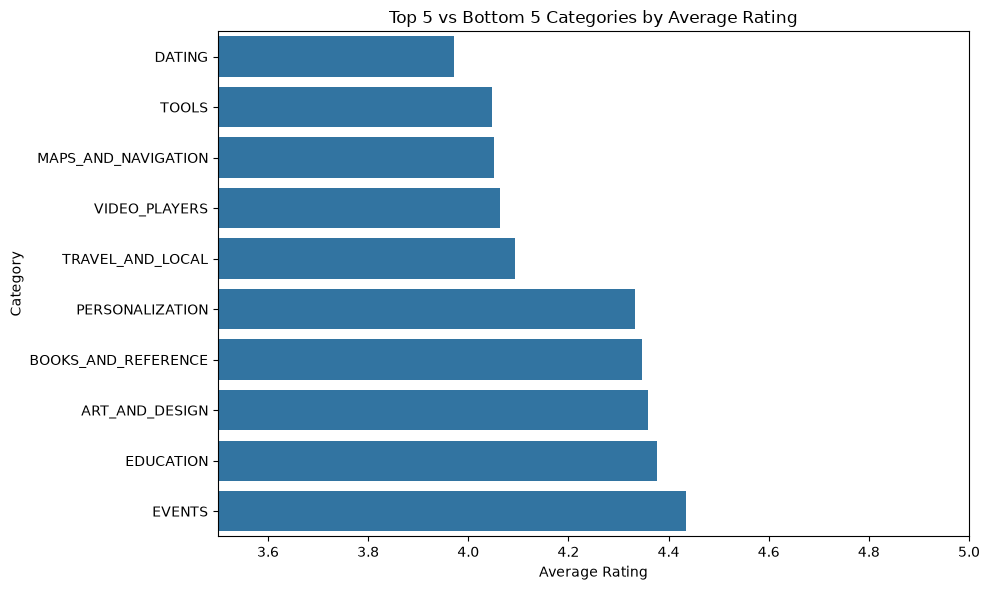

In [163]:
rating_comparison = pd.concat([
    category_ratings.head(5),
    category_ratings.tail(5)
])

rating_comparison = rating_comparison.sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_comparison.values,
    y=rating_comparison.index
)

plt.title('Top 5 vs Bottom 5 Categories by Average Rating')
plt.xlabel('Average Rating')
plt.ylabel('Category')
plt.xlim(3.5, 5)

plt.tight_layout()
plt.show()

In [164]:
type_ratings = (
    apps_clean.groupby('Type')['Rating']
    .agg(['mean', 'count'])
    .round(2)
)

print(type_ratings)

      mean  count
Type             
Free  4.18   8279
Paid  4.26    613


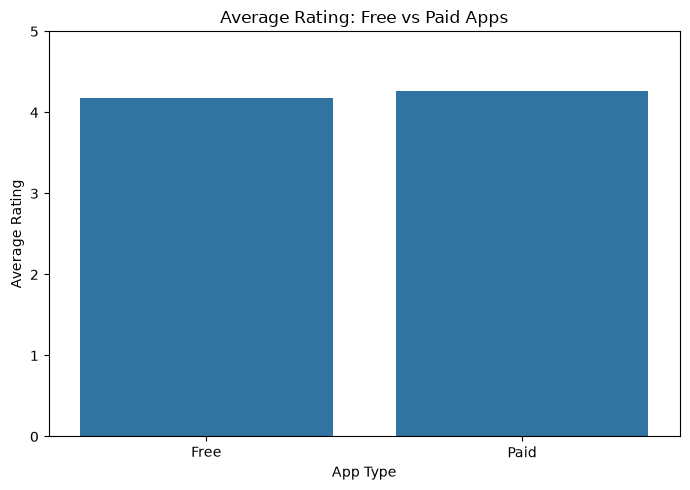

In [165]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=type_ratings.index,
    y=type_ratings['mean']
)

plt.title('Average Rating: Free vs Paid Apps')
plt.xlabel('App Type')
plt.ylabel('Average Rating')
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [166]:
category_installs = (
    apps_clean.groupby('Category')['Installs_Numeric']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Categories by Total Installs:")
print(category_installs.head(10))

Top 10 Categories by Total Installs:
Category
GAME                  31544024415
COMMUNICATION         24152276251
SOCIAL                12513867902
PRODUCTIVITY          12463091369
TOOLS                 11452771915
FAMILY                10041692505
PHOTOGRAPHY            9721247655
TRAVEL_AND_LOCAL       6361887146
VIDEO_PLAYERS          6222002720
NEWS_AND_MAGAZINES     5393217760
Name: Installs_Numeric, dtype: int64


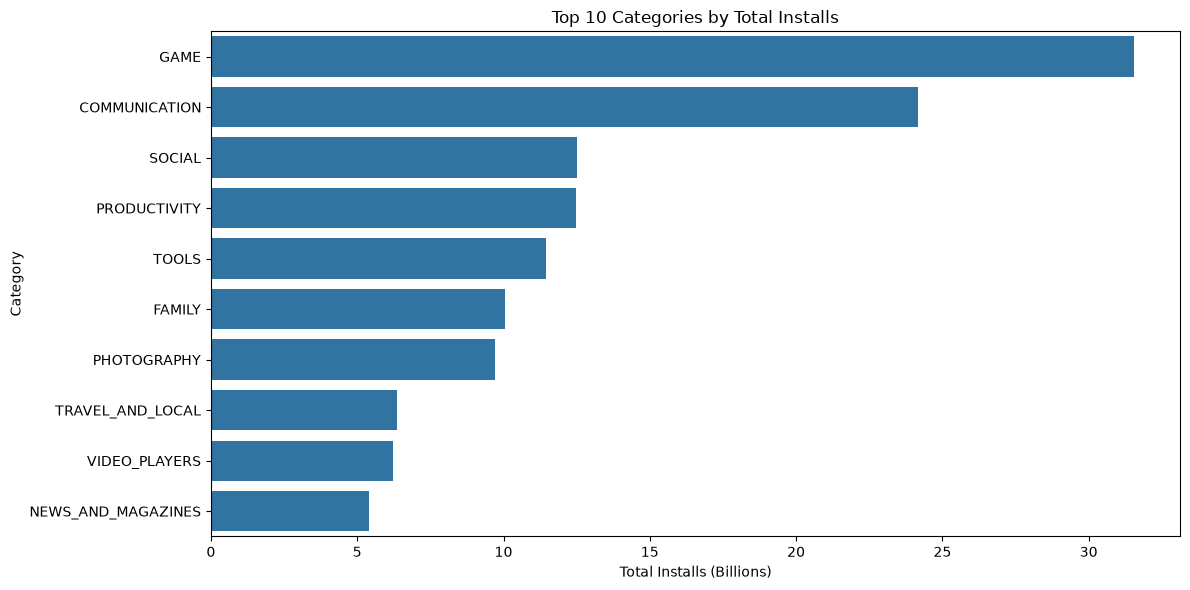

In [167]:
top_10_installs = category_installs.head(10) / 1e9

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_installs.values,
    y=top_10_installs.index
)

plt.title('Top 10 Categories by Total Installs')
plt.xlabel('Total Installs (Billions)')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

In [168]:
avg_installs = (
    apps_clean.groupby('Category')['Installs_Numeric']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Categories by Average Installs:")
print(avg_installs.head(10))

Top 10 Categories by Average Installs:
Category
COMMUNICATION         6.598983e+07
SOCIAL                4.469239e+07
VIDEO_PLAYERS         3.555430e+07
PRODUCTIVITY          3.062185e+07
PHOTOGRAPHY           3.019021e+07
GAME                  2.813918e+07
TRAVEL_AND_LOCAL      2.684341e+07
ENTERTAINMENT         2.212306e+07
NEWS_AND_MAGAZINES    2.042886e+07
TOOLS                 1.358573e+07
Name: Installs_Numeric, dtype: float64


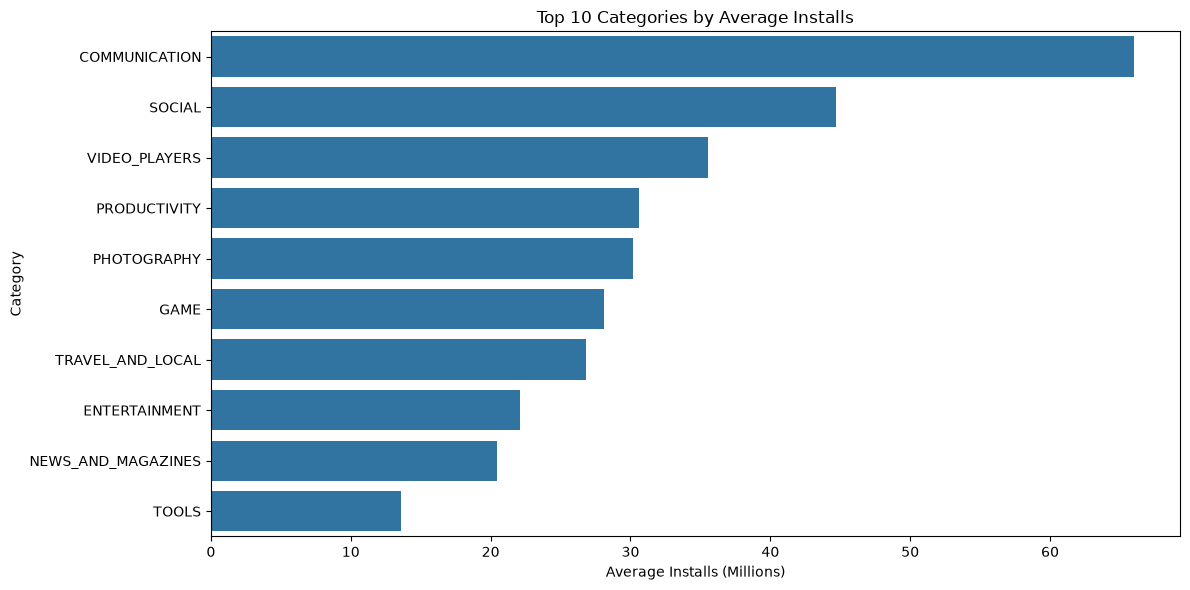

In [169]:
top_10_avg_installs = avg_installs.head(10) / 1e6

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_avg_installs.values,
    y=top_10_avg_installs.index
)

plt.title('Top 10 Categories by Average Installs')
plt.xlabel('Average Installs (Millions)')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

In [170]:
content_rating_counts = apps_clean['Content Rating'].value_counts()

print("Apps by Content Rating:")
print(content_rating_counts)

Apps by Content Rating:
Content Rating
Everyone           8382
Teen               1146
Mature 17+          447
Everyone 10+        377
Adults only 18+       3
Unrated               2
Name: count, dtype: int64


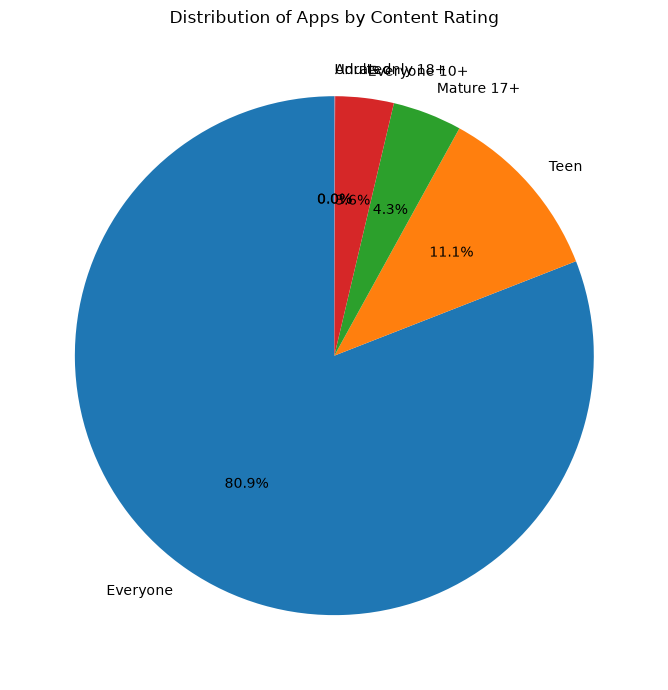

In [171]:
plt.figure(figsize=(9, 7))

plt.pie(
    content_rating_counts,
    labels=content_rating_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Apps by Content Rating')
plt.tight_layout()
plt.show()

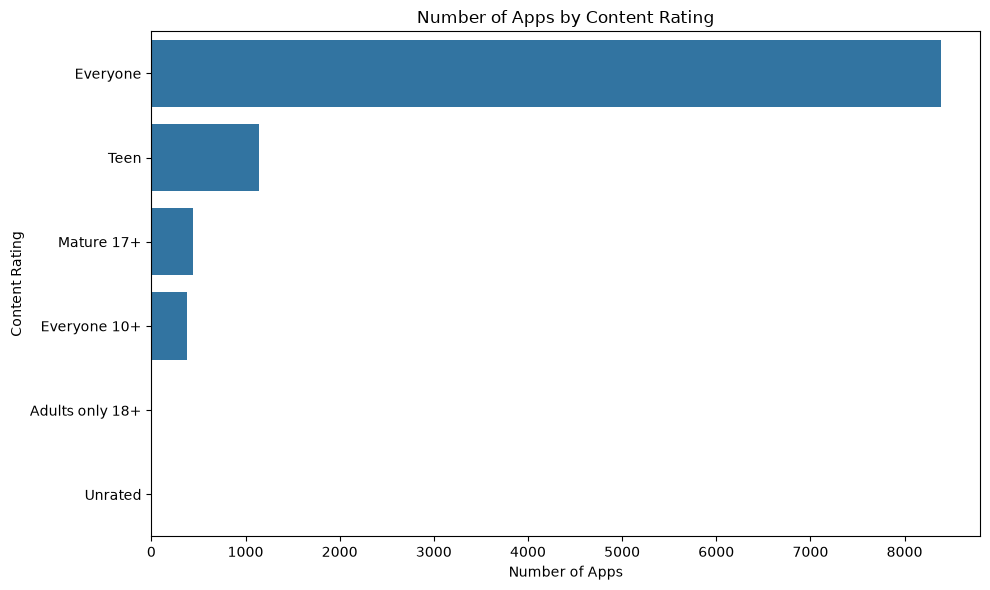

In [172]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=content_rating_counts.values,
    y=content_rating_counts.index
)

plt.title('Number of Apps by Content Rating')
plt.xlabel('Number of Apps')
plt.ylabel('Content Rating')

plt.tight_layout()
plt.show()

In [173]:
paid_apps = apps_clean[apps_clean['Price_Numeric'] > 0]

print("Total Paid Apps:", len(paid_apps))

print("\nPaid Apps Price Statistics:")
print(paid_apps['Price_Numeric'].describe())

Total Paid Apps: 765

Paid Apps Price Statistics:
count    765.000000
mean      13.955556
std       58.406966
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price_Numeric, dtype: float64


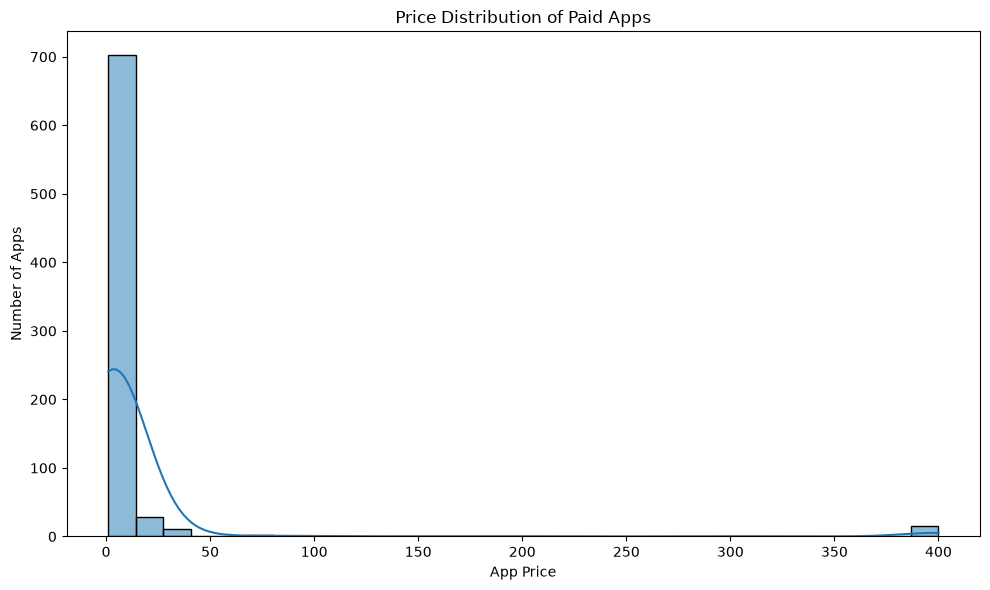

In [174]:
plt.figure(figsize=(10, 6))

sns.histplot(
    paid_apps['Price_Numeric'],
    bins=30,
    kde=True
)

plt.title('Price Distribution of Paid Apps')
plt.xlabel('App Price')
plt.ylabel('Number of Apps')

plt.tight_layout()
plt.show()

In [175]:
expensive_apps = (
    paid_apps[['App', 'Category', 'Price', 'Price_Numeric']]
    .sort_values(by='Price_Numeric', ascending=False)
    .head(10)
)

print(expensive_apps.to_string(index=False))

                              App  Category   Price  Price_Numeric
         I'm Rich - Trump Edition LIFESTYLE $400.00         400.00
                I Am Rich Premium   FINANCE $399.99         399.99
                        I am Rich   FINANCE $399.99         399.99
                        I am rich LIFESTYLE $399.99         399.99
                   I am Rich Plus    FAMILY $399.99         399.99
                       I am Rich!   FINANCE $399.99         399.99
                       💎 I'm rich LIFESTYLE $399.99         399.99
           most expensive app (H)    FAMILY $399.99         399.99
I'm Rich/Eu sou Rico/أنا غني/我很有錢 LIFESTYLE $399.99         399.99
               I AM RICH PRO PLUS   FINANCE $399.99         399.99


In [176]:
category_price = (
    paid_apps.groupby('Category')['Price_Numeric']
    .agg(['mean', 'count'])
    .sort_values(by='mean', ascending=False)
    .round(2)
)

print("Top 10 Categories by Average Paid App Price:")
print(category_price.head(10))

Top 10 Categories by Average Paid App Price:
                       mean  count
Category                          
FINANCE              170.64     17
LIFESTYLE            124.26     19
EVENTS               109.99      1
BUSINESS              14.61     12
FAMILY                12.95    187
MEDICAL               12.15     84
PRODUCTIVITY           8.96     28
PHOTOGRAPHY            6.11     20
MAPS_AND_NAVIGATION    5.39      5
SOCIAL                 5.32      3


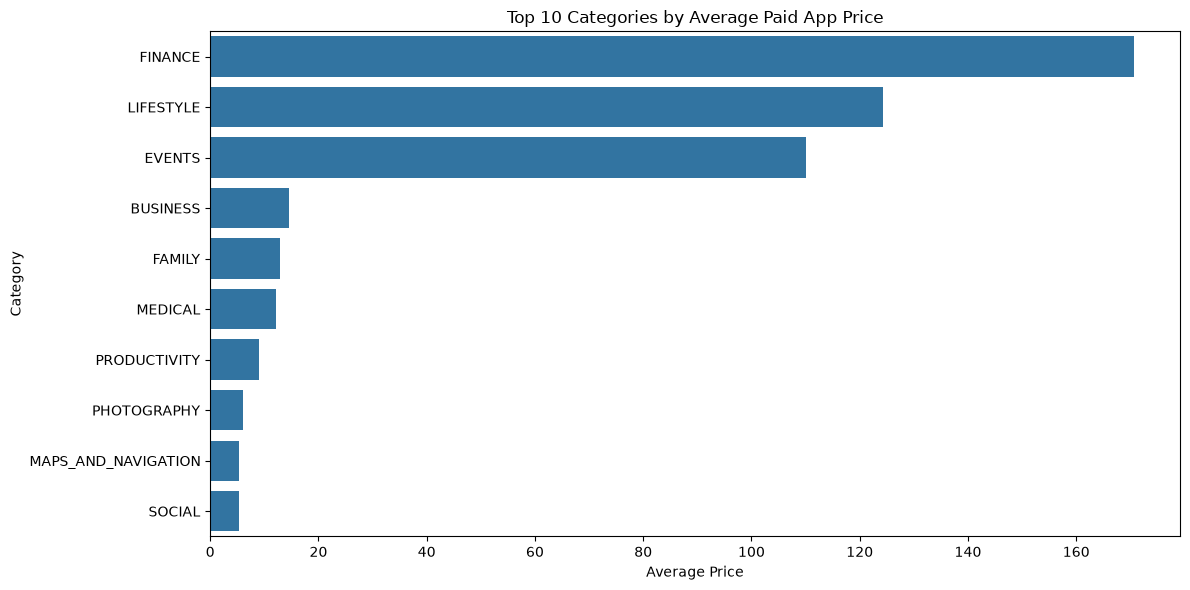

In [177]:
top_10_prices = category_price.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_prices['mean'],
    y=top_10_prices.index
)

plt.title('Top 10 Categories by Average Paid App Price')
plt.xlabel('Average Price')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

In [178]:
category_size = (
    apps_clean.groupby('Category')['Size_MB']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Categories by Average App Size (MB):")
print(category_size.head(10).round(2))

Top 10 Categories by Average App Size (MB):
Category
GAME                  44.13
FAMILY                27.93
TRAVEL_AND_LOCAL      24.52
SPORTS                24.18
ENTERTAINMENT         22.64
PARENTING             22.51
FOOD_AND_DRINK        22.06
HEALTH_AND_FITNESS    21.64
EDUCATION             20.08
AUTO_AND_VEHICLES     20.04
Name: Size_MB, dtype: float64


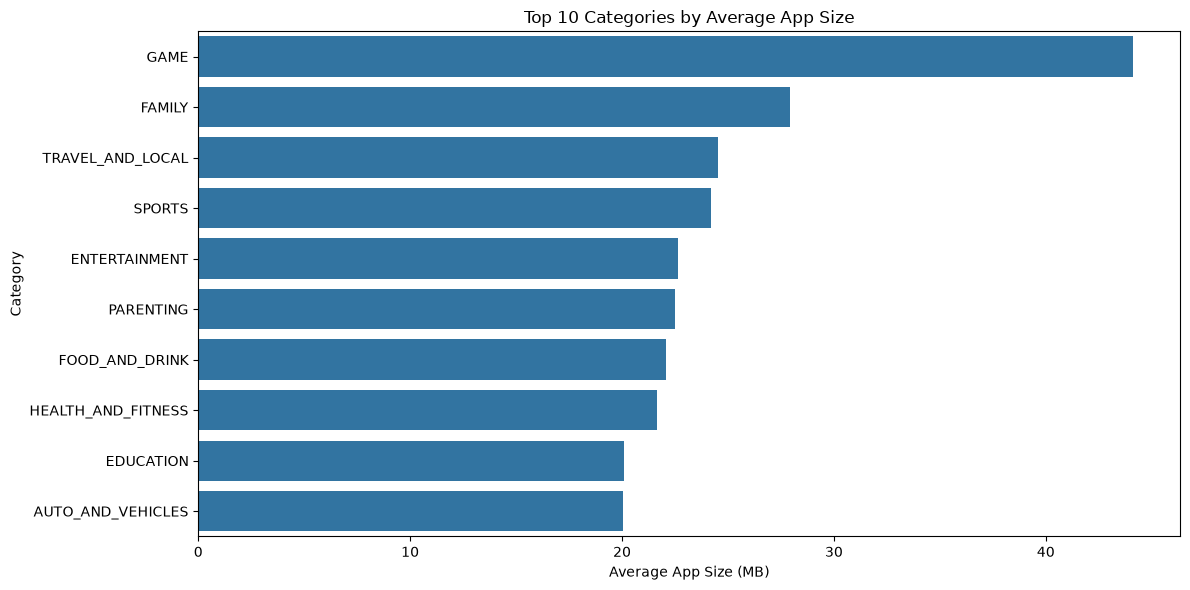

In [179]:
top_10_size = category_size.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_size.values,
    y=top_10_size.index
)

plt.title('Top 10 Categories by Average App Size')
plt.xlabel('Average App Size (MB)')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

In [180]:
app_category_check = (
    apps_clean.groupby('App')['Category']
    .nunique()
)

print("Apps with multiple categories:",
      (app_category_check > 1).sum())

print("\nMaximum categories per app:",
      app_category_check.max())

Apps with multiple categories: 85

Maximum categories per app: 2


In [181]:
multiple_category_apps = (
    apps_clean.groupby('App')['Category']
    .nunique()
)

multiple_category_apps = multiple_category_apps[
    multiple_category_apps > 1
].index

print(
    apps_clean[apps_clean['App'].isin(multiple_category_apps)]
    [['App', 'Category']]
    .sort_values('App')
    .to_string(index=False)
)

                                               App           Category
                                       8 Ball Pool               GAME
                                       8 Ball Pool               GAME
                                       8 Ball Pool               GAME
                                       8 Ball Pool               GAME
                                       8 Ball Pool               GAME
                                       8 Ball Pool               GAME
                                       8 Ball Pool             SPORTS
             A&E - Watch Full Episodes of TV Shows      ENTERTAINMENT
             A&E - Watch Full Episodes of TV Shows             FAMILY
                                     Angry Birds 2               GAME
                                     Angry Birds 2             FAMILY
                          Babbel – Learn Languages          EDUCATION
                          Babbel – Learn Languages          EDUCATION
                    

In [182]:
conflicting_apps = (
    apps_clean[['App', 'Category']]
    .drop_duplicates()
    .groupby('App')
    .filter(lambda x: x['Category'].nunique() > 1)
    .sort_values(['App', 'Category'])
)

print("Conflicting App-Category Combinations:")
print(conflicting_apps.to_string(index=False))

print("\nTotal Conflicting Combinations:", len(conflicting_apps))

Conflicting App-Category Combinations:
                                               App           Category
                                       8 Ball Pool               GAME
                                       8 Ball Pool             SPORTS
             A&E - Watch Full Episodes of TV Shows      ENTERTAINMENT
             A&E - Watch Full Episodes of TV Shows             FAMILY
                                     Angry Birds 2             FAMILY
                                     Angry Birds 2               GAME
                          Babbel – Learn Languages          EDUCATION
                          Babbel – Learn Languages             FAMILY
                            Barbie™ Fashion Closet             FAMILY
                            Barbie™ Fashion Closet               GAME
 Block Craft 3D: Building Simulator Games For Free             FAMILY
 Block Craft 3D: Building Simulator Games For Free               GAME
                                    Bubble Shooter 

In [183]:
# Get unique app-category combinations
app_category_map = apps_clean[['App', 'Category']].drop_duplicates()

# Identify apps having multiple categories
ambiguous_apps = (
    app_category_map.groupby('App')['Category']
    .nunique()
)

ambiguous_apps = ambiguous_apps[ambiguous_apps > 1].index

# Remove ambiguous apps from category mapping
unique_app_category = app_category_map[
    ~app_category_map['App'].isin(ambiguous_apps)
]

print("Total Unique Apps:", app_category_map['App'].nunique())
print("Ambiguous Apps:", len(ambiguous_apps))
print("Unambiguous Apps:", unique_app_category['App'].nunique())

print("\nRemaining Duplicate App Names:",
      unique_app_category['App'].duplicated().sum())

Total Unique Apps: 9659
Ambiguous Apps: 85
Unambiguous Apps: 9574

Remaining Duplicate App Names: 0


In [184]:
reviews_merged = reviews_clean.merge(
    unique_app_category,
    on='App',
    how='left',
    validate='many_to_one'
)

print("Merged Dataset Shape:", reviews_merged.shape)

print("\nMissing Categories:")
print(reviews_merged['Category'].isnull().sum())

print("\nCategory Distribution:")
print(reviews_merged['Category'].value_counts().head(10))

Merged Dataset Shape: (29692, 6)

Missing Categories:
2831

Category Distribution:
Category
GAME                  3399
FAMILY                1802
HEALTH_AND_FITNESS    1621
TOOLS                 1398
FINANCE               1336
TRAVEL_AND_LOCAL      1331
SPORTS                1216
MEDICAL               1156
PRODUCTIVITY          1135
DATING                1087
Name: count, dtype: int64


In [185]:
unmatched_apps = (
    reviews_merged.loc[
        reviews_merged['Category'].isnull(),
        'App'
    ]
    .value_counts()
)

print("Total Unmatched Apps:", len(unmatched_apps))

print("\nTop 20 Unmatched Apps:")
print(unmatched_apps.head(20))

Total Unmatched Apps: 81

Top 20 Unmatched Apps:
App
Episode - Choose Your Story                         124
Colorfy: Coloring Book for Adults - Free             97
8 Ball Pool                                          96
Clash Royale                                         96
Cut the Rope 2                                       90
Bubble Shooter                                       75
Home Street – Home Design Game                       57
Farm Heroes Saga                                     56
Duolingo: Learn Languages Free                       55
Flow Free                                            52
Easy - taxi, car, ridesharing                        46
Barbie™ Fashion Closet                               42
Banco Itaú                                           40
Banco do Brasil                                      40
Bancomer móvil                                       40
Candy Crush Saga                                     40
Dungeon Hunter Champions: Epic Online Action RPG   

In [186]:
all_app_names = set(apps_clean['App'].unique())

ambiguous_app_names = set(ambiguous_apps)

unmatched_app_names = set(unmatched_apps.index)

print("Unmatched Apps:", len(unmatched_app_names))

print("Ambiguous Apps:",
      len(unmatched_app_names & ambiguous_app_names))

print("Not Found in Apps Dataset:",
      len(unmatched_app_names - all_app_names))

Unmatched Apps: 81
Ambiguous Apps: 32
Not Found in Apps Dataset: 49


In [187]:
category_sentiment = pd.crosstab(
    reviews_merged['Category'],
    reviews_merged['Sentiment']
)

print(category_sentiment.head(10))

Sentiment            Negative  Neutral  Positive
Category                                        
ART_AND_DESIGN             47       58       229
AUTO_AND_VEHICLES          17       36       230
BEAUTY                     60       81       176
BOOKS_AND_REFERENCE        84      106       427
BUSINESS                  113      163       378
COMICS                      1        5        39
COMMUNICATION             177      158       520
DATING                    228      190       669
EDUCATION                  60       65       359
ENTERTAINMENT             138       83       345


In [188]:
category_sentiment_pct = pd.crosstab(
    reviews_merged['Category'],
    reviews_merged['Sentiment'],
    normalize='index'
) * 100

category_sentiment_pct = category_sentiment_pct.round(2)

print(category_sentiment_pct.head(10))

Sentiment            Negative  Neutral  Positive
Category                                        
ART_AND_DESIGN          14.07    17.37     68.56
AUTO_AND_VEHICLES        6.01    12.72     81.27
BEAUTY                  18.93    25.55     55.52
BOOKS_AND_REFERENCE     13.61    17.18     69.21
BUSINESS                17.28    24.92     57.80
COMICS                   2.22    11.11     86.67
COMMUNICATION           20.70    18.48     60.82
DATING                  20.98    17.48     61.55
EDUCATION               12.40    13.43     74.17
ENTERTAINMENT           24.38    14.66     60.95


In [189]:
print("Top 5 Categories by Positive Sentiment:")
print(
    category_sentiment_pct
    .sort_values('Positive', ascending=False)
    .head(5)
)

print("\nTop 5 Categories by Negative Sentiment:")
print(
    category_sentiment_pct
    .sort_values('Negative', ascending=False)
    .head(5)
)

Top 5 Categories by Positive Sentiment:
Sentiment           Negative  Neutral  Positive
Category                                       
COMICS                  2.22    11.11     86.67
AUTO_AND_VEHICLES       6.01    12.72     81.27
EVENTS                 10.26    10.90     78.85
HEALTH_AND_FITNESS     10.98    11.17     77.85
EDUCATION              12.40    13.43     74.17

Top 5 Categories by Negative Sentiment:
Sentiment      Negative  Neutral  Positive
Category                                  
GAME              35.66     5.50     58.84
SOCIAL            28.74    15.73     55.52
FAMILY            27.64    10.38     61.99
VIDEO_PLAYERS     25.46    17.79     56.75
ENTERTAINMENT     24.38    14.66     60.95


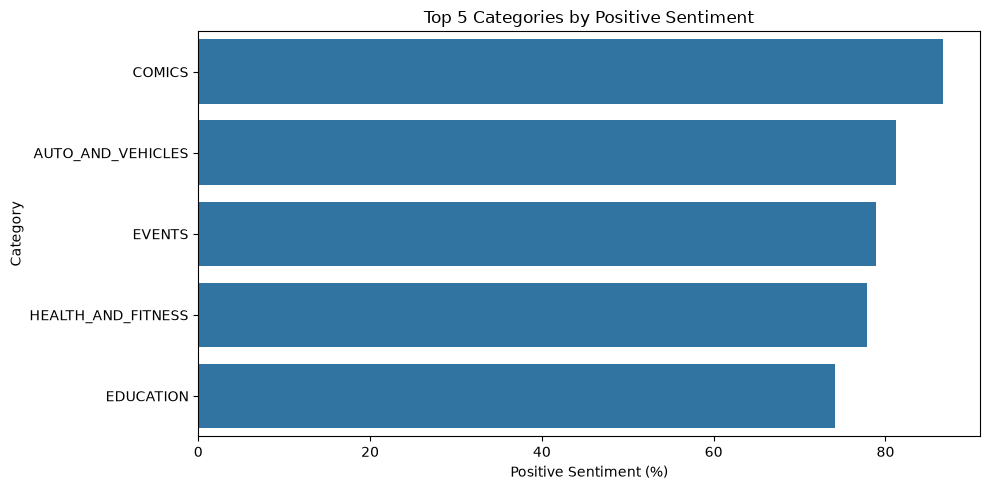

In [190]:
top_positive = category_sentiment_pct.sort_values(
    'Positive', ascending=False
).head(5)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_positive['Positive'],
    y=top_positive.index
)

plt.title('Top 5 Categories by Positive Sentiment')
plt.xlabel('Positive Sentiment (%)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

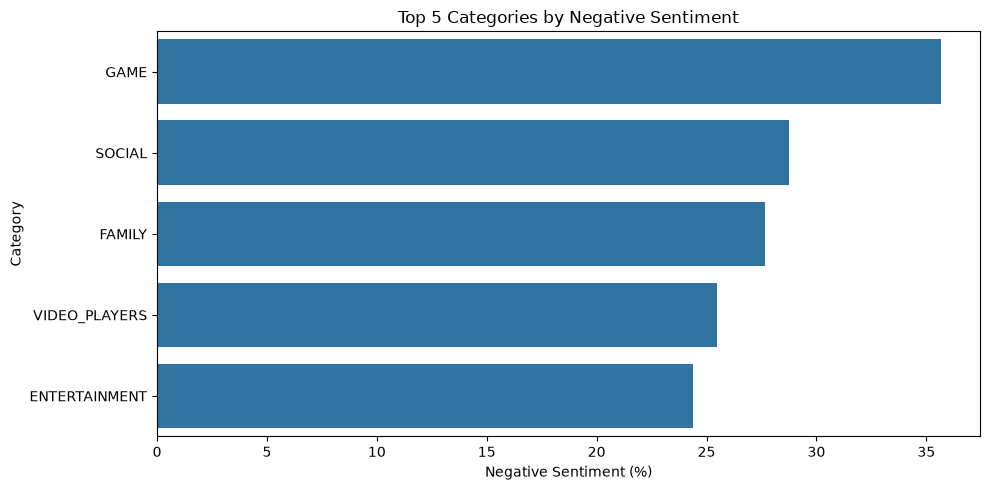

In [191]:
top_negative = category_sentiment_pct.sort_values(
    'Negative', ascending=False
).head(5)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_negative['Negative'],
    y=top_negative.index
)

plt.title('Top 5 Categories by Negative Sentiment')
plt.xlabel('Negative Sentiment (%)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

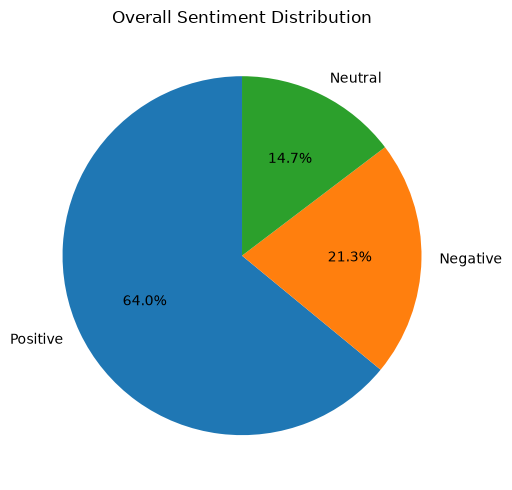

In [192]:
sentiment_counts = reviews_clean['Sentiment'].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Overall Sentiment Distribution')
plt.tight_layout()
plt.show()

In [193]:
category_polarity = (
    reviews_merged
    .dropna(subset=['Category'])
    .groupby('Category')['Sentiment_Polarity']
    .mean()
    .sort_values(ascending=False)
)

print("Top 5 Categories by Average Sentiment Polarity:")
print(category_polarity.head(5))

print("\nBottom 5 Categories by Average Sentiment Polarity:")
print(category_polarity.tail(5))

Top 5 Categories by Average Sentiment Polarity:
Category
COMICS               0.449810
EVENTS               0.375086
AUTO_AND_VEHICLES    0.343119
PARENTING            0.313316
EDUCATION            0.300062
Name: Sentiment_Polarity, dtype: float64

Bottom 5 Categories by Average Sentiment Polarity:
Category
ENTERTAINMENT    0.138105
VIDEO_PLAYERS    0.136103
FAMILY           0.119083
SOCIAL           0.108144
GAME             0.066770
Name: Sentiment_Polarity, dtype: float64


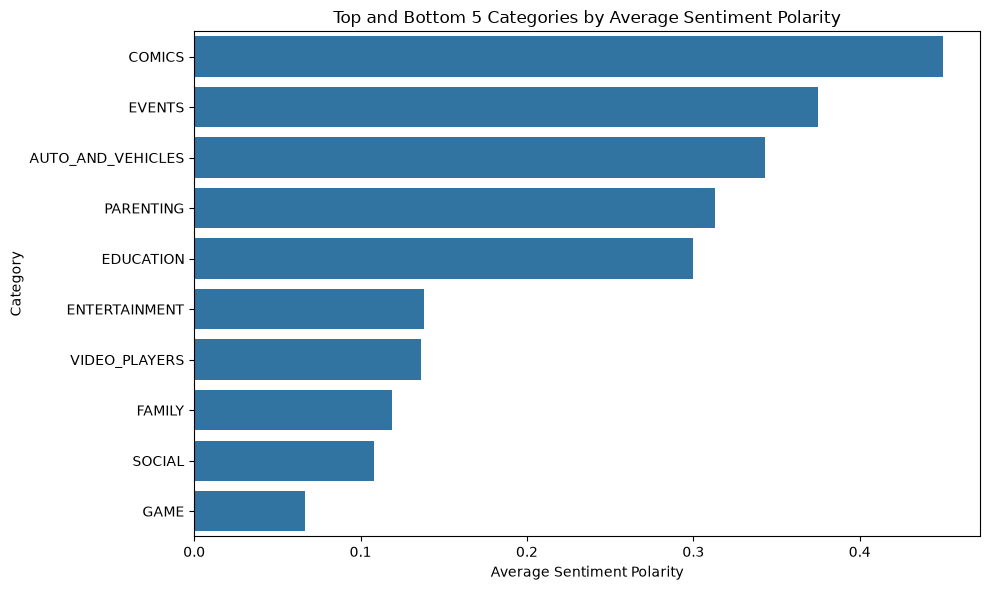

In [194]:
top_bottom_polarity = pd.concat([
    category_polarity.head(5),
    category_polarity.tail(5)
])

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_bottom_polarity.values,
    y=top_bottom_polarity.index
)

plt.title('Top and Bottom 5 Categories by Average Sentiment Polarity')
plt.xlabel('Average Sentiment Polarity')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

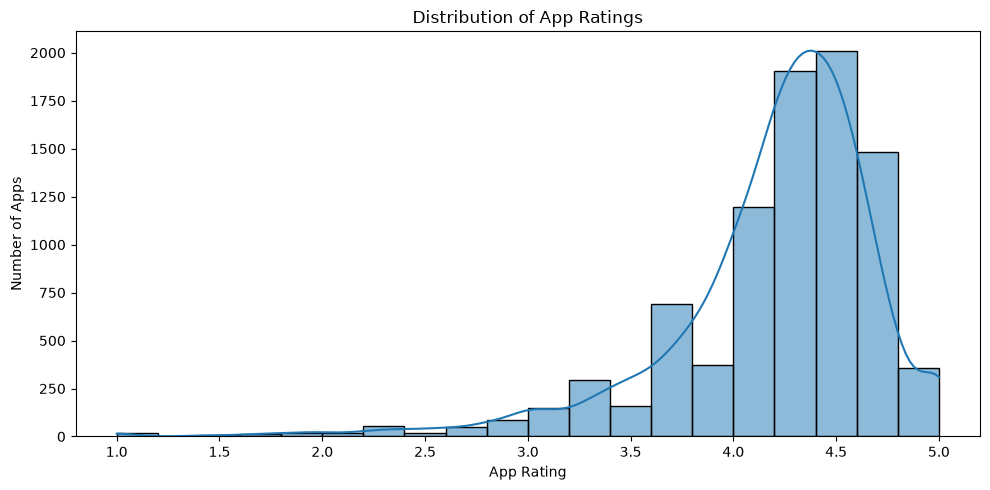

In [195]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=apps_clean,
    x='Rating',
    bins=20,
    kde=True
)

plt.title('Distribution of App Ratings')
plt.xlabel('App Rating')
plt.ylabel('Number of Apps')

plt.tight_layout()
plt.show()

In [196]:
apps_clean['Rating'].describe()

count    8892.000000
mean        4.187877
std         0.522377
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64

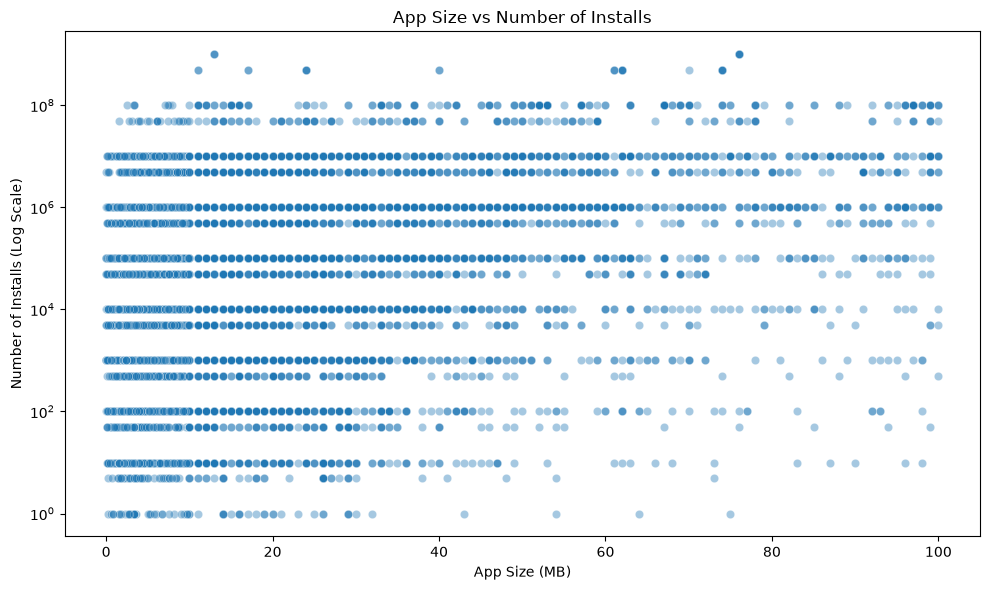

In [197]:
size_install_data = apps_clean.dropna(
    subset=['Size_MB', 'Installs_Numeric']
)

size_install_data = size_install_data[
    size_install_data['Installs_Numeric'] > 0
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_install_data,
    x='Size_MB',
    y='Installs_Numeric',
    alpha=0.4
)

plt.yscale('log')

plt.title('App Size vs Number of Installs')
plt.xlabel('App Size (MB)')
plt.ylabel('Number of Installs (Log Scale)')

plt.tight_layout()
plt.show()

In [198]:
pearson_corr = size_install_data[
    ['Size_MB', 'Installs_Numeric']
].corr(method='pearson').iloc[0, 1]

spearman_corr = size_install_data[
    ['Size_MB', 'Installs_Numeric']
].corr(method='spearman').iloc[0, 1]

print("Pearson Correlation:", round(pearson_corr, 4))
print("Spearman Correlation:", round(spearman_corr, 4))

Pearson Correlation: 0.1689
Spearman Correlation: 0.3418


In [199]:
paid_apps = apps_clean[
    apps_clean['Price_Numeric'] > 0
].copy()

paid_apps['Estimated_Revenue'] = (
    paid_apps['Price_Numeric'] *
    paid_apps['Installs_Numeric']
)

print("Paid Apps:", len(paid_apps))

print("\nTop 10 Apps by Estimated Revenue:")
print(
    paid_apps[
        ['App', 'Category', 'Price_Numeric',
         'Installs_Numeric', 'Estimated_Revenue']
    ]
    .sort_values('Estimated_Revenue', ascending=False)
    .head(10)
)

Paid Apps: 765

Top 10 Apps by Estimated Revenue:
                                App     Category  Price_Numeric  \
2241                      Minecraft       FAMILY           6.99   
4347                      Minecraft       FAMILY           6.99   
5351                      I am rich    LIFESTYLE         399.99   
5356              I Am Rich Premium      FINANCE         399.99   
4034                  Hitman Sniper         GAME           0.99   
7417  Grand Theft Auto: San Andreas         GAME           6.99   
2883            Facetune - For Free  PHOTOGRAPHY           5.99   
5578        Sleep as Android Unlock    LIFESTYLE           5.99   
8804            DraStic DS Emulator         GAME           4.99   
4367       I'm Rich - Trump Edition    LIFESTYLE         400.00   

      Installs_Numeric  Estimated_Revenue  
2241          10000000         69900000.0  
4347          10000000         69900000.0  
5351            100000         39999000.0  
5356             50000         19999

In [200]:
duplicate_paid_apps = paid_apps[
    paid_apps.duplicated(subset='App', keep=False)
].sort_values('App')

print("Duplicate Paid App Records:",
      len(duplicate_paid_apps))

print("\nDuplicate App Names:",
      duplicate_paid_apps['App'].nunique())

print("\nDuplicate Records:")
print(
    duplicate_paid_apps[
        ['App', 'Category', 'Price_Numeric', 'Installs_Numeric']
    ].head(20)
)

Duplicate Paid App Records: 18

Duplicate App Names: 9

Duplicate Records:
                                                   App         Category  \
6652                                       Camera FV-5      PHOTOGRAPHY   
2913                                       Camera FV-5      PHOTOGRAPHY   
8785                      Dr. Panda & Toto's Treehouse           FAMILY   
2192                      Dr. Panda & Toto's Treehouse           FAMILY   
852             Fuzzy Numbers: Pre-K Number Foundation        EDUCATION   
4301            Fuzzy Numbers: Pre-K Number Foundation           FAMILY   
6919                                        HD Widgets  PERSONALIZATION   
3405                                        HD Widgets  PERSONALIZATION   
2251  Human Anatomy Atlas 2018: Complete 3D Human Body          MEDICAL   
9574  Human Anatomy Atlas 2018: Complete 3D Human Body          MEDICAL   
2241                                         Minecraft           FAMILY   
4347                     

In [201]:
duplicate_check = (
    duplicate_paid_apps
    .groupby('App')
    .agg(
        Records=('App', 'count'),
        Categories=('Category', 'nunique'),
        Prices=('Price_Numeric', 'nunique'),
        Installs=('Installs_Numeric', 'nunique')
    )
    .sort_values('App')
)

print(duplicate_check.to_string())

                                                  Records  Categories  Prices  Installs
App                                                                                    
Camera FV-5                                             2           1       1         1
Dr. Panda & Toto's Treehouse                            2           1       1         1
Fuzzy Numbers: Pre-K Number Foundation                  2           2       1         1
HD Widgets                                              2           1       1         1
Human Anatomy Atlas 2018: Complete 3D Human Body        2           1       1         1
Minecraft                                               2           1       1         1
Moco+ - Chat, Meet People                               2           1       1         1
The Game of Life                                        2           1       1         1
Toca Life: City                                         2           2       1         1


In [202]:
paid_app_summary = (
    paid_apps
    .groupby('App')
    .agg(
        Category=('Category', 'first'),
        Category_Count=('Category', 'nunique'),
        Price=('Price_Numeric', 'first'),
        Installs=('Installs_Numeric', 'first')
    )
    .reset_index()
)

# Keep apps having only one category
paid_app_summary = paid_app_summary[
    paid_app_summary['Category_Count'] == 1
].copy()

# Calculate estimated revenue
paid_app_summary['Estimated_Revenue'] = (
    paid_app_summary['Price'] *
    paid_app_summary['Installs']
)

print("Original Paid Records:", len(paid_apps))
print("Unique Paid Apps:", paid_app_summary['App'].nunique())
print("Apps Excluded Due to Ambiguous Categories:",
      paid_apps['App'].nunique() -
      paid_app_summary['App'].nunique())

print("Clean Paid App Dataset Shape:",
      paid_app_summary.shape)

Original Paid Records: 765
Unique Paid Apps: 754
Apps Excluded Due to Ambiguous Categories: 2
Clean Paid App Dataset Shape: (754, 6)


In [203]:
category_revenue = (
    paid_app_summary
    .groupby('Category')
    .agg(
        Total_Apps=('App', 'nunique'),
        Total_Installs=('Installs', 'sum'),
        Estimated_Revenue=('Estimated_Revenue', 'sum')
    )
    .sort_values(
        'Estimated_Revenue',
        ascending=False
    )
)

print(category_revenue.to_string())

                     Total_Apps  Total_Installs  Estimated_Revenue
Category                                                          
FAMILY                      183        20649814       1.136798e+08
LIFESTYLE                    19         1179110       5.758394e+07
GAME                         82        20999965       4.068864e+07
FINANCE                      17          185602       2.572668e+07
PHOTOGRAPHY                  19         1878740       8.547768e+06
PERSONALIZATION              81         3258794       6.796948e+06
MEDICAL                      83          560833       5.957536e+06
TOOLS                        78         1727441       5.464821e+06
SPORTS                       24         1243815       4.706212e+06
PRODUCTIVITY                 28         1412055       4.313375e+06
COMMUNICATION                27         1360050       4.247364e+06
WEATHER                       8          812000       4.181380e+06
HEALTH_AND_FITNESS           15          474110       1.426069

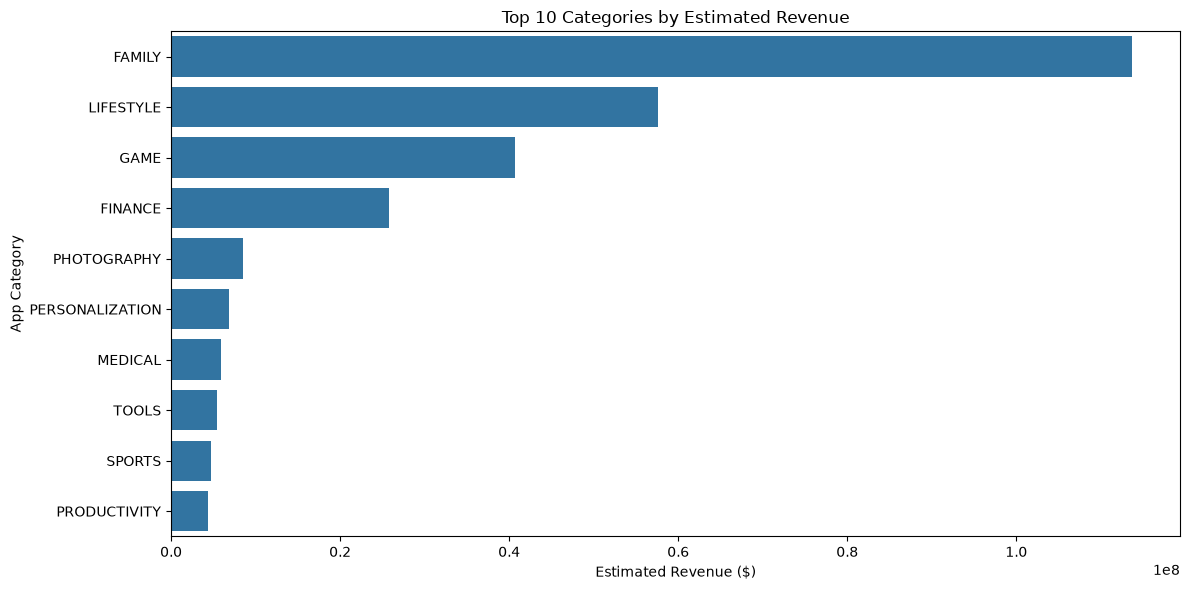

In [204]:
top_10_revenue = category_revenue.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_revenue,
    x='Estimated_Revenue',
    y='Category'
)

plt.title('Top 10 Categories by Estimated Revenue')
plt.xlabel('Estimated Revenue ($)')
plt.ylabel('App Category')
plt.tight_layout()
plt.show()

In [205]:
from textblob import TextBlob

sample_text = "This app is amazing and very useful!"

blob = TextBlob(sample_text)

print("Polarity:", blob.sentiment.polarity)
print("Subjectivity:", blob.sentiment.subjectivity)

Polarity: 0.5437500000000001
Subjectivity: 0.45


In [206]:
reviews_clean['TextBlob_Polarity'] = (
    reviews_clean['Translated_Review']
    .apply(lambda text: TextBlob(str(text)).sentiment.polarity)
)

print(reviews_clean[
    ['Translated_Review', 'Sentiment_Polarity', 'TextBlob_Polarity']
].head(10))

                                    Translated_Review  Sentiment_Polarity  \
0   I like eat delicious food. That's I'm cooking ...                1.00   
1     This help eating healthy exercise regular basis                0.25   
3          Works great especially going grocery store                0.40   
4                                        Best idea us                1.00   
5                                            Best way                1.00   
6                                             Amazing                0.60   
8                                Looking forward app,                0.00   
9               It helpful site ! It help foods get !                0.00   
10                                          good you.                0.70   
11  Useful information The amount spelling errors ...                0.20   

    TextBlob_Polarity  
0                1.00  
1                0.25  
3                0.40  
4                1.00  
5                1.00  
6       

In [207]:
def classify_sentiment(polarity):
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'


reviews_clean['TextBlob_Sentiment'] = (
    reviews_clean['TextBlob_Polarity']
    .apply(classify_sentiment)
)

print(reviews_clean['TextBlob_Sentiment'].value_counts())

print("\nSentiment Percentages:")
print(
    reviews_clean['TextBlob_Sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TextBlob_Sentiment
Positive    19014
Negative     6322
Neutral      4356
Name: count, dtype: int64

Sentiment Percentages:
TextBlob_Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: proportion, dtype: float64


In [208]:
comparison = pd.crosstab(
    reviews_clean['Sentiment'],
    reviews_clean['TextBlob_Sentiment'],
    rownames=['Original Sentiment'],
    colnames=['TextBlob Sentiment']
)

print("Sentiment Comparison:")
print(comparison)

agreement = (
    reviews_clean['Sentiment'] ==
    reviews_clean['TextBlob_Sentiment']
).mean() * 100

print("\nClassification Agreement:", round(agreement, 2), "%")

Sentiment Comparison:
TextBlob Sentiment  Negative  Neutral  Positive
Original Sentiment                             
Negative                6321        0         0
Neutral                    0     4356         0
Positive                   1        0     19014

Classification Agreement: 100.0 %


In [209]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [211]:
print("Current Shape:", apps_clean.shape)

print("Corrupt Category Rows:")
print(apps_clean[apps_clean['Category'] == '1.9'])

print("Invalid Rating Rows:")
print(apps_clean[apps_clean['Rating'] > 5])

Current Shape: (10357, 16)
Corrupt Category Rows:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver, Size_MB, Installs_Numeric, Price_Numeric]
Index: []
Invalid Rating Rows:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver, Size_MB, Installs_Numeric, Price_Numeric]
Index: []


In [212]:
reviews_clean = reviews.copy()

# Remove rows with missing review text
reviews_clean = reviews_clean.dropna(
    subset=['Translated_Review']
)

# Remove exact duplicate rows
reviews_clean = reviews_clean.drop_duplicates()

print("Reviews Shape:", reviews_clean.shape)
print("Missing Values:", reviews_clean.isnull().sum().sum())
print("Duplicate Rows:", reviews_clean.duplicated().sum())

Reviews Shape: (29692, 5)
Missing Values: 0
Duplicate Rows: 0


In [213]:
reviews_clean['TextBlob_Polarity'] = (
    reviews_clean['Translated_Review']
    .apply(lambda text: TextBlob(str(text)).sentiment.polarity)
)

def classify_sentiment(polarity):
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'

reviews_clean['TextBlob_Sentiment'] = (
    reviews_clean['TextBlob_Polarity']
    .apply(classify_sentiment)
)

print(reviews_clean['TextBlob_Sentiment'].value_counts())

TextBlob_Sentiment
Positive    19014
Negative     6322
Neutral      4356
Name: count, dtype: int64


In [214]:
top_10_categories = (
    apps_clean['Category']
    .value_counts()
    .head(10)
    .reset_index()
)

top_10_categories.columns = ['Category', 'App_Count']

fig = px.bar(
    top_10_categories,
    x='Category',
    y='App_Count',
    title='Top 10 Google Play Store Categories',
    color='App_Count',
    hover_data=['App_Count'],
    text='App_Count'
)

fig.update_layout(
    xaxis_title='App Category',
    yaxis_title='Number of Apps',
    xaxis_tickangle=-45,
    template='plotly_white'
)

fig.show()

# Project Conclusion – Google Play Store Analysis

## 1. Project Overview

This project explores the Google Play Store ecosystem using Python, Pandas, NumPy, Matplotlib, Seaborn, TextBlob, and Plotly.

The analysis focuses on app categories, ratings, installations, app sizes, pricing patterns, and user review sentiment to understand market trends and opportunities for app developers.

## 2. Key Findings

- **Category Analysis:** FAMILY has the highest number of apps (1,943), while GAME leads in total installations with approximately 31.54 billion.
- **Ratings Analysis:** The average app rating is approximately 4.19, indicating generally positive user ratings.
- **Size and Installs:** App size has a weak positive relationship with installations (Pearson correlation: 0.169). App size alone is not a strong predictor of popularity.
- **Pricing Analysis:** Approximately 9,592 apps are free and 765 are paid. FAMILY has the highest estimated paid-app revenue, followed by LIFESTYLE and GAME.
- **Sentiment Analysis:** Approximately 64.04% of reviews are positive, 21.29% negative, and 14.67% neutral.

## 3. Three Data-Driven Insights for App Developers

**Insight 1: Choose the Right Market Category**

FAMILY has the highest number of apps, while GAME has the highest total installations. Developers should evaluate both competition and user demand before selecting a category.

**Insight 2: Prioritize User Experience**

Approximately 64% of reviews are positive. However, GAME has the highest negative-review proportion among categories at approximately 35.66%. Developers should focus on performance, usability, regular improvements, and customer feedback.

**Insight 3: Focus on Value Rather Than App Size or Price Alone**

App size has only a weak relationship with installations. The revenue analysis also shows that FAMILY leads estimated paid-app revenue. Developers should focus on useful features, pricing strategy, and customer value rather than assuming that larger or more expensive apps will perform better.

## 4. Limitations

- Missing ratings and unavailable app sizes were retained where appropriate.
- Installation counts are approximate values reported by the dataset.
- Estimated revenue is calculated using listed app prices multiplied by reported installations. It does not represent actual earnings.
- Sentiment classification is based on TextBlob polarity and may not fully understand sarcasm, context, or complex expressions.
- Category-wise sentiment analysis excludes apps with ambiguous category mappings.

## 5. Final Conclusion

The analysis highlights the importance of understanding market competition, user satisfaction, pricing strategies, and app performance before launching a new application.

This project demonstrates practical skills in data cleaning, exploratory data analysis, data visualization, sentiment analysis, and deriving business insights using Python.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, TextBlob, Plotly, and Jupyter Notebook.